Aditya Chopra, 3P14, Roll No. 1024160115, Assignment - 7

In [1]:
!pip install -q nltk pandas numpy matplotlib

import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import hashlib
import re
import string
import math

for pkg in [
    "punkt",
    "punkt_tab",
    "stopwords",
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng"
]:
    nltk.download(pkg, quiet=True)

from nltk.tokenize import sent_tokenize, word_tokenize, RegexpTokenizer
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.util import bigrams

STOP = set(stopwords.words("english"))

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
ROLL_NO = 1024160115
NAME = "Aditya Chopra"

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

print("Roll Number:", ROLL_NO)
print("Name:", NAME)

Roll Number: 1024160115
Name: Aditya Chopra


In [3]:
def generate_dataset(roll_no):

    rng = random.Random(int(roll_no))

    subjects = [
        ("LMS", ["LMS", "lms"]),
        ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]),
        ("VPN", ["VPN"]),
        ("email", ["email", "e-mail"]),
        ("password", ["password"]),
        ("portal", ["student portal"]),
        ("projector", ["projector"]),
        ("laptop", ["laptop"]),
        ("MATLAB", ["MATLAB", "Matlab"]),
        ("Python", ["Python"]),
        ("printer", ["printer"]),
        ("server", ["server"])
    ]

    actions = [
        "is not working",
        "keeps disconnecting",
        "failed to open",
        "is running slowly",
        "crashes while opening",
        "stopped responding",
        "is showing an error",
        "was working yesterday",
        "has stopped syncing",
        "keeps asking for login"
    ]

    user_actions = [
        "cannot access",
        "can't open",
        "couldn't connect to",
        "am unable to use",
        "tried restarting",
        "was locked out of",
        "keep getting logged out of",
        "reinstalled"
    ]

    contexts = [
        "after resetting my password",
        "during the lab",
        "on my laptop",
        "since yesterday",
        "after the latest update",
        "when I use mobile hotspot",
        "before the assignment deadline",
        "while uploading the file",
        "after restarting the system",
        "when connected to campus Wi-Fi"
    ]

    endings = [
        "Please help.",
        "Can you check this?",
        "I have tried several times!",
        "It worked yesterday.",
        "I don't know what changed.",
        "The same problem occurs again.",
        "Is there another solution?",
        "It works on another computer.",
        "This is urgent.",
        "Please resolve it."
    ]

    challenges = {
        "negation": [
            "The Wi-Fi works, but the VPN doesn't.",
            "Why isn't the portal opening?",
            "I can't login and I didn't change anything.",
            "It's not the laptop; it's the server.",
            "Nothing works and nobody has replied.",
            "The printer won't print; it isn't jammed."
        ],

        "numbers": [
            "Python 3.12 was installed yesterday.",
            "The file is 95.5% uploaded.",
            "Error code 0x80070005 appears.",
            "I need Windows 11 by 5.30 p.m. today.",
            "Only 2 of 30 PCs boot after 3.5 hours.",
            "Version 2.0.1 crashes at 99%."
        ],

        "identifiers": [
            "Email me at helpdesk@university.edu.",
            "See https://lms.thapar.edu/help for details.",
            "My roll no. is 1023-03-021.",
            "Ticket #4521 is still open.",
            "Call me on +91 98765 43210 or 0175-239-3201.",
            "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."
        ],

        "punctuation": [
            "I tried again... still no response!!!",
            "The LMS says 'Not Submitted'.",
            "Dr. Rao's lab PC (No. 14) is down.",
            "Is it fixed?? Pls reply ASAP :(",
            "The state-of-the-art lab (Lab-3) is closed.",
            "Re-installing didn't help; log-in still fails!"
        ]
    }

    tickets = []

    for _ in range(8 + int(roll_no) % 5):

        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)

        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"

        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"

        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"

        tickets.append(text[0].upper() + text[1:])

    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))

    rng.shuffle(tickets)

    df = pd.DataFrame({
        "Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))],
        "Ticket_Text": tickets
    })

    focus = [
        f"T{i:02d}"
        for i in sorted(
            rng.sample(range(1, len(tickets) + 1), 2)
        )
    ]

    fingerprint = hashlib.md5(
        ("|".join(tickets) + str(int(roll_no))).encode()
    ).hexdigest()[:8].upper()

    return df, focus, fingerprint


df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)

print("Fingerprint:", FINGERPRINT)
print("Focus Ticket IDs:", FOCUS)
print("Total Tickets:", len(df))

display(df)

df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Fingerprint: A1C0CDDD
Focus Ticket IDs: ['T04', 'T09']
Total Tickets: 12


,Ticket_ID,Ticket_Text
0,T01,Projector is running slowly after resetting my...
1,T02,The email is not working. I have tried several...
2,T03,The e-mail was working yesterday. Is there ano...
3,T04,The state-of-the-art lab (Lab-3) is closed.
4,T05,See https://lms.thapar.edu/help for details.
5,T06,The projector is running slowly. It works on a...
6,T07,The MATLAB has stopped syncing. Please help.
7,T08,The printer keeps asking for login. Is there a...
8,T09,Email has stopped syncing when I use mobile ho...
9,T10,Student portal was working yesterday when conn...


In [4]:
def is_punct(token):
    return all(ch in string.punctuation for ch in token)


def process_ticket(text):

    sentences = sent_tokenize(text)

    tokens = [
        t.lower()
        for s in sentences
        for t in word_tokenize(s)
    ]

    punct = [
        t for t in tokens
        if is_punct(t)
    ]

    stops = [
        t for t in tokens
        if t in STOP
    ]

    final = [
        t for t in tokens
        if not is_punct(t) and t not in STOP
    ]

    return {
        "sentences": sentences,
        "tokens": tokens,
        "punct": punct,
        "stops": stops,
        "final": final
    }


print("Preprocessing function ready!")

Preprocessing function ready!


In [5]:
results = []

for _, row in df.iterrows():

    ticket_id = row["Ticket_ID"]
    text = row["Ticket_Text"]

    processed = process_ticket(text)

    results.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(processed["sentences"]),
        "Tokens": len(processed["tokens"]),
        "Punctuation Tokens": len(processed["punct"]),
        "Stopwords": len(processed["stops"]),
        "Unique Tokens": len(set(processed["tokens"])),
        "Final Tokens": len(processed["final"])
    })

q1_df = pd.DataFrame(results)

display(q1_df)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,3,11,7
1,T02,2,12,2,5,12,5
2,T03,2,11,2,4,11,5
3,T04,1,9,3,2,9,4
4,T05,1,7,2,1,7,4
5,T06,2,12,2,4,11,6
6,T07,2,9,2,2,8,5
7,T08,2,12,2,4,12,6
8,T09,2,16,2,5,15,9
9,T10,2,15,2,4,13,9


In [6]:
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": q1_df["Sentences"].sum(),
    "Tokens": q1_df["Tokens"].sum(),
    "Punctuation Tokens": q1_df["Punctuation Tokens"].sum(),
    "Stopwords": q1_df["Stopwords"].sum(),
    "Unique Tokens": q1_df["Unique Tokens"].sum(),
    "Final Tokens": q1_df["Final Tokens"].sum()
}

q1_df_total = pd.concat(
    [q1_df, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_df_total)

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,12,2,3,11,7
1,T02,2,12,2,5,12,5
2,T03,2,11,2,4,11,5
3,T04,1,9,3,2,9,4
4,T05,1,7,2,1,7,4
5,T06,2,12,2,4,11,6
6,T07,2,9,2,2,8,5
7,T08,2,12,2,4,12,6
8,T09,2,16,2,5,15,9
9,T10,2,15,2,4,13,9


In [7]:
for ticket_id in FOCUS:

    text = df.loc[
        df["Ticket_ID"] == ticket_id,
        "Ticket_Text"
    ].iloc[0]

    processed = process_ticket(text)

    print("\nTicket ID:", ticket_id)
    print("Original Text:", text)

    print("\nActual Tokens:")
    print(processed["tokens"])

    print("\nPunctuation Tokens:")
    print(processed["punct"])

    print("\nStopwords:")
    print(processed["stops"])

    print("\nFinal Tokens:")
    print(processed["final"])

    print("-" * 70)


Ticket ID: T04
Original Text: The state-of-the-art lab (Lab-3) is closed.

Actual Tokens:
['the', 'state-of-the-art', 'lab', '(', 'lab-3', ')', 'is', 'closed', '.']

Punctuation Tokens:
['(', ')', '.']

Stopwords:
['the', 'is']

Final Tokens:
['state-of-the-art', 'lab', 'lab-3', 'closed']
----------------------------------------------------------------------

Ticket ID: T09
Original Text: Email has stopped syncing when I use mobile hotspot. I have tried several times!

Actual Tokens:
['email', 'has', 'stopped', 'syncing', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'i', 'have', 'tried', 'several', 'times', '!']

Punctuation Tokens:
['.', '!']

Stopwords:
['has', 'when', 'i', 'i', 'have']

Final Tokens:
['email', 'stopped', 'syncing', 'use', 'mobile', 'hotspot', 'tried', 'several', 'times']
----------------------------------------------------------------------


In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",

    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",

    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work."
]

for line in TEST_LINES:
    print(line)

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


In [9]:
all_text = " ".join(df["Ticket_Text"])

long_words = re.findall(
    r"\b[A-Za-z]{6,}\b",
    all_text
)

print("Words longer than 5 letters:")
print(long_words)

Words longer than 5 letters:
['Projector', 'running', 'slowly', 'resetting', 'password', 'Please', 'working', 'several', 'working', 'yesterday', 'another', 'solution', 'closed', 'thapar', 'details', 'projector', 'running', 'slowly', 'another', 'computer', 'MATLAB', 'stopped', 'syncing', 'Please', 'printer', 'asking', 'another', 'solution', 'stopped', 'syncing', 'mobile', 'hotspot', 'several', 'Student', 'portal', 'working', 'yesterday', 'connected', 'campus', 'worked', 'yesterday', 'Nothing', 'nobody', 'replied', 'Version', 'crashes']


In [10]:
number_pattern = r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])"

numbers = re.findall(number_pattern, all_text)

print("Extracted numbers:")
print(numbers)

Extracted numbers:
['3', '2.0.1', '99']


In [11]:
number_pattern = r"(?<![\w.])\d+(?:,\d{3})*(?:\.\d+)*(?![\w.])"

numbers = re.findall(number_pattern, all_text)

print("Extracted numbers:")
print(numbers)

Extracted numbers:
['3', '2.0.1', '99']


In [12]:
capitalized_words = re.findall(
    r"\b[A-Z][a-zA-Z]*\b",
    all_text
)

print("Capitalized words:")
print(capitalized_words)

print("Total:", len(capitalized_words))

Capitalized words:
['Projector', 'Please', 'The', 'I', 'The', 'Is', 'The', 'Lab', 'See', 'The', 'It', 'The', 'MATLAB', 'Please', 'The', 'Is', 'Email', 'I', 'I', 'Student', 'Wi', 'Fi', 'It', 'Nothing', 'Version']
Total: 25


In [13]:
vowel_words = re.findall(
    r"\b[AEIOUaeiou][a-zA-Z]*\b",
    all_text
)

print("Words beginning with vowels:")
print(vowel_words)

Words beginning with vowels:
['is', 'after', 'email', 'is', 'I', 'e', 'Is', 'another', 'of', 'art', 'is', 'edu', 'is', 'It', 'on', 'another', 'asking', 'Is', 'another', 'Email', 'I', 'use', 'I', 'It', 'and', 'at']


In [14]:
def replace_sensitive_info(text):

    # Replace email addresses
    text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
    )

    # Replace URLs
    text = re.sub(
        r"(?:https?://|www\.)[^\s]+",
        "<URL>",
        text
    )

    # Replace phone numbers
    text = re.sub(
        r"(?<!\w)(?:\+91[-\s]?)?(?:\d{5}[-\s]?\d{5}|\d{4}[-\s]\d{6})(?!\w)",
        "<PHONE>",
        text
    )

    return text


print("REPLACEMENT ON TEST LINES")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Modified:", replace_sensitive_info(line))


print("\nREPLACEMENT ON GENERATED TICKETS")

for text in df["Ticket_Text"]:
    print("\nOriginal:", text)
    print("Modified:", replace_sensitive_info(text))

REPLACEMENT ON TEST LINES

Original: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Modified: Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Original: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Modified: Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Original: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Modified: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.

REPLACEMENT ON GENERATED TICKETS

Original: Projector is running slowly after resetting my password. Please help.
Modified: Projector is running slowly after resetting my password. Please help.

Original: The email is not working. I have tried several times!
Modified: The email is not working. I have tried several times!

Original: The e-mail was working yesterday. Is there another solution?
Modified: The e-mail was working yest

In [15]:
pattern = r"""
(?:https?://|www\.)[^\s]+
|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}
|\+?\d{1,3}[-\s]?(?:\d{5}[-\s]?\d{5}|\d{4}[-\s]\d{6})
|\d+(?:\.\d+)+
|\d+(?:,\d{3})+
|\d+
|[A-Za-z]+(?:[-'][A-Za-z]+)+
|[A-Za-z]+
|[^\w\s]
"""

custom_tokenizer = RegexpTokenizer(
    pattern,
    flags=re.VERBOSE
)


def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

In [16]:
for line in TEST_LINES:

    print("\nOriginal Text:")
    print(line)

    print("\nCustom Tokenizer:")
    print(my_tokenize(line))

    print("\nNLTK word_tokenize:")
    print(word_tokenize(line))

    print("-" * 70)


Original Text:
Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.

Custom Tokenizer:
['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']

NLTK word_tokenize:
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
----------------------------------------------------------------------

Original Text:
Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Custom Tokenizer:
['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

NLTK word_tokenize:
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'd

In [17]:
different_tickets = []

for _, row in df.iterrows():

    text = row["Ticket_Text"]

    custom_tokens = my_tokenize(text)
    nltk_tokens = word_tokenize(text)

    if custom_tokens != nltk_tokens:

        different_tickets.append({
            "Ticket_ID": row["Ticket_ID"],
            "Custom Tokens": custom_tokens,
            "NLTK Tokens": nltk_tokens
        })


print("Total tickets:", len(df))

print(
    "Tickets tokenized differently:",
    len(different_tickets)
)

for ticket in different_tickets:

    print("\nTicket:", ticket["Ticket_ID"])
    print("Custom:", ticket["Custom Tokens"])
    print("NLTK:", ticket["NLTK Tokens"])

Total tickets: 12
Tickets tokenized differently: 2

Ticket: T04
Custom: ['The', 'state-of-the-art', 'lab', '(', 'Lab', '-', '3', ')', 'is', 'closed', '.']
NLTK: ['The', 'state-of-the-art', 'lab', '(', 'Lab-3', ')', 'is', 'closed', '.']

Ticket: T05
Custom: ['See', 'https://lms.thapar.edu/help', 'for', 'details', '.']
NLTK: ['See', 'https', ':', '//lms.thapar.edu/help', 'for', 'details', '.']


In [18]:
print("""
Differences between word_tokenize() and my_tokenize():

1. The custom tokenizer preserves Wi-Fi and state-of-the-art
   as single hyphenated tokens.

2. It preserves contractions such as isn't as one token.

3. It keeps decimals such as 95.5 and versions such as 2.0.1
   together.

4. It keeps email addresses and URLs as single tokens.

5. It can preserve phone numbers as single tokens.

NLTK word_tokenize() uses standard language tokenization,
whereas the custom tokenizer follows a pattern designed
specifically for IT-support tickets.
""")


Differences between word_tokenize() and my_tokenize():

1. The custom tokenizer preserves Wi-Fi and state-of-the-art
   as single hyphenated tokens.

2. It preserves contractions such as isn't as one token.

3. It keeps decimals such as 95.5 and versions such as 2.0.1
   together.

4. It keeps email addresses and URLs as single tokens.

5. It can preserve phone numbers as single tokens.

NLTK word_tokenize() uses standard language tokenization,
whereas the custom tokenizer follows a pattern designed
specifically for IT-support tickets.



In [19]:
all_final_tokens = []

for text in df["Ticket_Text"]:

    processed = process_ticket(text)

    all_final_tokens.extend(processed["final"])


unique_final_tokens = sorted(set(all_final_tokens))

print("Unique final tokens:")
print(unique_final_tokens)

print("\nTotal unique final tokens:", len(unique_final_tokens))

Unique final tokens:
['//lms.thapar.edu/help', '2.0.1', '99', 'another', 'asking', 'campus', 'closed', 'computer', 'connected', 'crashes', 'details', 'e-mail', 'email', 'help', 'hotspot', 'https', 'keeps', 'lab', 'lab-3', 'login', 'matlab', 'mobile', 'nobody', 'nothing', 'password', 'please', 'portal', 'printer', 'projector', 'replied', 'resetting', 'running', 'see', 'several', 'slowly', 'solution', 'state-of-the-art', 'stopped', 'student', 'syncing', 'times', 'tried', 'use', 'version', 'wi-fi', 'worked', 'working', 'works', 'yesterday']

Total unique final tokens: 49


In [21]:
suffix_candidates = ["ing", "ed", "ly", "es", "s"]

suffix_counts = {
    suffix: sum(
        1 for word in unique_final_tokens
        if word.endswith(suffix)
        and len(word) > len(suffix) + 2
    )
    for suffix in suffix_candidates
}

selected_suffix = max(suffix_counts, key=suffix_counts.get)

if suffix_counts[selected_suffix] == 0:
    selected_suffix = "s"

regexp_stemmer = RegexpStemmer(
    regexp=selected_suffix + "$",
    min=4
)

print("Suffix counts:", suffix_counts)
print("Selected suffix:", selected_suffix)
print("RegexpStemmer initialized successfully!")

Suffix counts: {'ing': 6, 'ed': 6, 'ly': 1, 'es': 2, 's': 7}
Selected suffix: s
RegexpStemmer initialized successfully!


In [22]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return "a"

    elif tag.startswith("V"):
        return "v"

    elif tag.startswith("N"):
        return "n"

    elif tag.startswith("R"):
        return "r"

    return "n"


pos_tags = pos_tag(unique_final_tokens)

lemma_results = {}

for word, tag in pos_tags:

    pos = get_wordnet_pos(tag)

    lemma_results[word] = lemmatizer.lemmatize(
        word,
        pos
    )

In [23]:
comparison = []

for word in unique_final_tokens:

    porter_result = porter.stem(word)

    lancaster_result = lancaster.stem(word)

    regexp_result = regexp_stemmer.stem(word)

    lemma_result = lemma_results[word]

    comparison.append({
        "Original Word": word,
        "Porter Stemmer": porter_result,
        "Lancaster Stemmer": lancaster_result,
        "Regexp Stemmer": regexp_result,
        "WordNet Lemmatizer": lemma_result
    })


comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Original Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
0,//lms.thapar.edu/help,//lms.thapar.edu/help,//lms.thapar.edu/help,//lms.thapar.edu/help,//lms.thapar.edu/help
1,2.0.1,2.0.1,2.0.1,2.0.1,2.0.1
2,99,99,99,99,99
3,another,anoth,anoth,another,another
4,asking,ask,ask,asking,ask
5,campus,campu,camp,campu,campus
6,closed,close,clos,closed,close
7,computer,comput,comput,computer,computer
8,connected,connect,connect,connected,connect
9,crashes,crash,crash,crashe,crash


In [24]:
different_words = comparison_df[
    comparison_df.iloc[:, 1:].nunique(axis=1) > 1
]

print("Words where outputs differ:")

display(different_words)

print("Total differing words:", len(different_words))

Words where outputs differ:


,Original Word,Porter Stemmer,Lancaster Stemmer,Regexp Stemmer,WordNet Lemmatizer
3,another,anoth,anoth,another,another
4,asking,ask,ask,asking,ask
5,campus,campu,camp,campu,campus
6,closed,close,clos,closed,close
7,computer,comput,comput,computer,computer
8,connected,connect,connect,connected,connect
9,crashes,crash,crash,crashe,crash
15,https,http,https,http,https
21,mobile,mobil,mobl,mobile,mobile
22,nobody,nobodi,nobody,nobody,nobody


Total differing words: 31


In [25]:
print("Compare the outputs in the table above.")

print("""
Over-stemming:
When a stemmer removes too much of a word and produces
an incorrect or meaningless root.

Under-stemming:
When related words are not reduced to a common stem.

The RegexpStemmer can also produce undesirable results
because it removes the selected suffix using a fixed rule.
""")

Compare the outputs in the table above.

Over-stemming:
When a stemmer removes too much of a word and produces
an incorrect or meaningless root.

Under-stemming:
When related words are not reduced to a common stem.

The RegexpStemmer can also produce undesirable results
because it removes the selected suffix using a fixed rule.



In [26]:
S1 = []
S2 = []
S3 = []

for text in df["Ticket_Text"]:

    processed = process_ticket(text)

    # S1: All tokens
    S1.extend(processed["tokens"])

    # S2: Tokens without punctuation
    S2.extend([
        token for token in processed["tokens"]
        if not is_punct(token)
    ])

    # S3: Final tokens after stopword removal
    S3.extend(processed["final"])


# S4: S3 after Porter stemming
S4 = [
    porter.stem(word)
    for word in S3
]


print("S1 tokens:", len(S1))
print("S2 tokens:", len(S2))
print("S3 tokens:", len(S3))
print("S4 tokens:", len(S4))

S1 tokens: 129
S2 tokens: 105
S3 tokens: 68
S4 tokens: 68


In [27]:
def corpus_statistics(name, corpus):

    total_tokens = len(corpus)

    unique_tokens = len(set(corpus))

    ttr = (
        unique_tokens / total_tokens
        if total_tokens > 0 else 0
    )

    return {
        "Corpus": name,
        "Total Tokens": total_tokens,
        "Unique Tokens": unique_tokens,
        "TTR": round(ttr, 4)
    }


statistics = pd.DataFrame([
    corpus_statistics("S1", S1),
    corpus_statistics("S2", S2),
    corpus_statistics("S3", S3),
    corpus_statistics("S4", S4)
])

display(statistics)

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,129,73,0.5659
1,S2,105,66,0.6286
2,S3,68,49,0.7206
3,S4,68,47,0.6912


In [28]:
freq_S1 = FreqDist(S1)

freq_S3 = FreqDist(S3)

print("TOP 10 WORDS IN S1")

for word, frequency in freq_S1.most_common(10):
    print(word, ":", frequency)


print("\nTOP 10 WORDS IN S3")

for word, frequency in freq_S3.most_common(10):
    print(word, ":", frequency)

TOP 10 WORDS IN S1
. : 16
is : 6
the : 6
working : 3
i : 3
yesterday : 3
another : 3
has : 3
projector : 2
running : 2

TOP 10 WORDS IN S3
working : 3
yesterday : 3
another : 3
projector : 2
running : 2
slowly : 2
please : 2
help : 2
email : 2
tried : 2


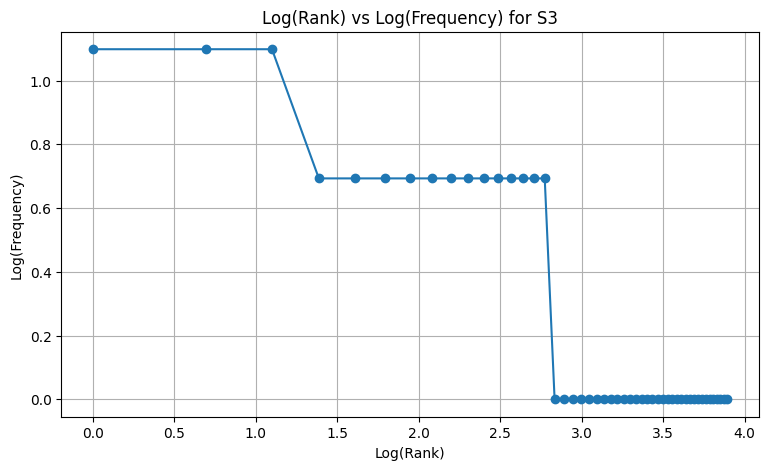

In [29]:
frequencies = sorted(
    freq_S3.values(),
    reverse=True
)

ranks = np.arange(1, len(frequencies) + 1)

log_ranks = np.log(ranks)

log_frequencies = np.log(frequencies)

plt.figure(figsize=(9, 5))

plt.plot(
    log_ranks,
    log_frequencies,
    marker="o"
)

plt.xlabel("Log(Rank)")
plt.ylabel("Log(Frequency)")

plt.title("Log(Rank) vs Log(Frequency) for S3")

plt.grid(True)

plt.show()

In [30]:
bigram_S1 = FreqDist(bigrams(S1))

bigram_S3 = FreqDist(bigrams(S3))


print("TOP 5 BIGRAMS OF S1")

for bigram, frequency in bigram_S1.most_common(5):
    print(bigram, ":", frequency)


print("\nTOP 5 BIGRAMS OF S3")

for bigram, frequency in bigram_S3.most_common(5):
    print(bigram, ":", frequency)

TOP 5 BIGRAMS OF S1
('.', 'the') : 4
('projector', 'is') : 2
('is', 'running') : 2
('running', 'slowly') : 2
('.', 'please') : 2

TOP 5 BIGRAMS OF S3
('projector', 'running') : 2
('running', 'slowly') : 2
('please', 'help') : 2
('tried', 'several') : 2
('several', 'times') : 2


In [31]:
print("""
(a) Why does TTR change from S1 to S4?

TTR is calculated as the ratio of unique tokens to total tokens.
From S1 to S4, punctuation and stopwords are removed.
Porter stemming also converts different forms of related words
into common stems. Therefore, both total and unique token counts
change, which affects TTR.


(b) Give one example where word_tokenize() and your tokenizer differ.

For example, word_tokenize() may split the word Wi-Fi into
separate tokens, whereas our custom tokenizer preserves
Wi-Fi as a single token.


(c) Give one example where stemming produces an undesirable result.

For example, Porter stemming may convert university into univers.
The resulting stem is not a meaningful dictionary word.


(d) Give one example where POS-aware lemmatization preserves
meaning better than stemming.

For example, the word running, when tagged as a verb,
is converted into run by POS-aware lemmatization.
It produces a meaningful dictionary form, whereas a stemmer
may produce a truncated form.
""")


(a) Why does TTR change from S1 to S4?

TTR is calculated as the ratio of unique tokens to total tokens.
From S1 to S4, punctuation and stopwords are removed.
Porter stemming also converts different forms of related words
into common stems. Therefore, both total and unique token counts
change, which affects TTR.


(b) Give one example where word_tokenize() and your tokenizer differ.

For example, word_tokenize() may split the word Wi-Fi into
separate tokens, whereas our custom tokenizer preserves
Wi-Fi as a single token.


(c) Give one example where stemming produces an undesirable result.

For example, Porter stemming may convert university into univers.
The resulting stem is not a meaningful dictionary word.


(d) Give one example where POS-aware lemmatization preserves
meaning better than stemming.

For example, the word running, when tagged as a verb,
is converted into run by POS-aware lemmatization.
It produces a meaningful dictionary form, whereas a stemmer
may produce a truncat

In [32]:
for i, line in enumerate(TEST_LINES, 1):

    print(f"\nTEST LINE {i}")
    print("-" * 60)

    print("Long words:")
    print(re.findall(r"\b[A-Za-z]{6,}\b", line))

    print("\nNumbers:")
    print(re.findall(number_pattern, line))

    print("\nCapitalized words:")
    print(re.findall(r"\b[A-Z][a-zA-Z]*\b", line))

    print("\nWords beginning with vowels:")
    print(re.findall(r"\b[AEIOUaeiou][a-zA-Z]*\b", line))

    print("\nReplaced text:")
    print(replace_sensitive_info(line))


TEST LINE 1
------------------------------------------------------------
Long words:
['helpdesk', 'thapar', 'thapar', 'thapar']

Numbers:
[]

Capitalized words:
['Mail']

Words beginning with vowels:
['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Replaced text:
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

TEST LINE 2
------------------------------------------------------------
Long words:
['Version']

Numbers:
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']

Capitalized words:
['Call', 'Version', 'Rs']

Words beginning with vowels:
['or', 'is']

Replaced text:
Call <PHONE>, <PHONE> or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.

TEST LINE 3
------------------------------------------------------------
Long words:
[]

Numbers:
['5.30']

Capitalized words:
['The']

Words beginning with vowels:
['of', 'art', 'isn', 'open', 'in', 'at']

Replaced text:
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn

In [33]:
df.to_csv("generated_dataset.csv", index=False)

q1_df_total.to_csv("Q1_preprocessing.csv", index=False)

comparison_df.to_csv("Q4_stemming_comparison.csv", index=False)

statistics.to_csv("Q5_corpus_statistics.csv", index=False)

print("All output files saved successfully!")

All output files saved successfully!
